# Heart Disease Prediction System

**Live Deployment Link:** _PASTE YOUR STREAMLIT URL HERE AFTER DEPLOYING (see Step 10)_

**Course:** AIC354 — Machine Learning Fundamentals
**Institution:** COMSATS University Islamabad, Lahore Campus
**Instructor:** Dr. Rao Muhammad Adeel Nawab
**Student:** Mujtaba Naveed | FA24-BSE-183
**Assignment:** Assignment 2, Task 2 — Heart Disease Prediction System

This notebook follows the **exact same steps** as the instructor-provided
`Titanic_Passenger_Survival_Recommended.ipynb`, applied to the
[UCI Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease)
(Cleveland database, 303 patients, CC BY 4.0 license).

## Assignment constraint
Only **4 input attributes** were selected (as required), all naturally
categorical in the source data — which mirrors the Titanic project's
all-categorical design (PClass, Gender, Sibling, Embarked) and lets this
notebook reuse the exact same Label Encoding approach with no changes to
the underlying method:

| Attribute | Meaning | Categories |
|---|---|---|
| `Sex` | Patient's biological sex | Male, Female |
| `ChestPainType` | Type of chest pain reported | TypicalAngina, AtypicalAngina, NonAnginal, Asymptomatic |
| `FastingBloodSugar` | Fasting blood sugar > 120 mg/dl | Yes, No |
| `ExerciseAngina` | Angina induced by exercise | Yes, No |

**Target:** `HeartDisease` (Yes/No) — the original UCI `num` column (0-4) was
collapsed into binary Yes/No, per the UCI dataset's own stated convention
("distinguish presence (1,2,3,4) from absence (0)") — exactly analogous to
Titanic's binary `Survived` (Yes/No).

## Table of Contents
1. Import Libraries
2. Load Sample Data
3. Understand and Pre-process Sample Data
4. Feature Extraction
5. Label Encoding the Sample Data
6. Execute the Training Phase
7. Execute the Testing Phase
8. Execute the Application Phase
9. Execute the Feedback Phase
10. Deploy as a Public Web App


### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.

(Identical imports to the Titanic notebook -- same method, new dataset.)
"""

import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable

import matplotlib.pyplot as plt
import seaborn as sns


### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads the Heart Disease sample dataset (derived from
the UCI Cleveland database, reduced to 4 input attributes per the assignment
constraint) into a pandas DataFrame, and displays it.
"""

sample_data = pd.read_csv("sample-data.csv")

print("\n\nSample Data:")
print("============\n")

pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data)




Sample Data:

        Sex   ChestPainType FastingBloodSugar ExerciseAngina HeartDisease
0      Male   TypicalAngina               Yes             No           No
1      Male    Asymptomatic                No            Yes          Yes
2      Male    Asymptomatic                No            Yes          Yes
3      Male      NonAnginal                No             No           No
4    Female  AtypicalAngina                No             No           No
5      Male  AtypicalAngina                No             No           No
6    Female    Asymptomatic                No             No          Yes
7    Female    Asymptomatic                No            Yes           No
8      Male    Asymptomatic                No             No          Yes
9      Male    Asymptomatic               Yes            Yes          Yes
10     Male    Asymptomatic                No             No           No
11   Female  AtypicalAngina                No             No           No
12     Male      NonAn

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Checking for missing values and viewing the class balance of the target.
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:", sample_data["Sex"].count())
print("========================================\n")

print("\nMissing values per column:\n", sample_data.isnull().sum())
print("\nHeartDisease class balance:\n", sample_data["HeartDisease"].value_counts())




Attributes in Sample Data:

Index(['Sex', 'ChestPainType', 'FastingBloodSugar', 'ExerciseAngina',
       'HeartDisease'],
      dtype='str')


Number of Instances in Sample Data: 303


Missing values per column:
 Sex                  0
ChestPainType        0
FastingBloodSugar    0
ExerciseAngina       0
HeartDisease         0
dtype: int64

HeartDisease class balance:
 HeartDisease
No     164
Yes    139
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data

**Correctness note:** the source UCI data has `?` placeholders for missing
values in two columns (`ca`, `thal`). Neither of those columns was selected
as one of our 4 input attributes, and the four columns we did select
(`Sex`, `ChestPainType`, `FastingBloodSugar`, `ExerciseAngina`) have **zero**
missing values across all 303 patients (verified in Step 3.1 above), so no
row-dropping or imputation is needed here -- unlike a naive copy of the
Titanic steps, we explicitly checked this rather than assuming it.

#### Step 4: Feature Extraction

The 4 selected input attributes (`Sex`, `ChestPainType`,
`FastingBloodSugar`, `ExerciseAngina`) plus the target (`HeartDisease`) are
already isolated in `sample-data.csv` -- this mirrors the Titanic dataset's
`PClass, Gender, Sibling, Embarked, Survived` layout exactly, so no further
column extraction is required here.

### Step 5: Label Encoding the Sample Data (Input and Output converted to Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains Label Encoders.
Label Encoding converts categorical values (like 'Male', 'Female',
'Asymptomatic') into numeric codes that machine learning algorithms can
work with.

Steps:
1. Define sample label categories for each attribute.
2. Initialize a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder with its respective category values.
"""

sex = pd.DataFrame({"Sex": ["Male", "Female"]})
cp = pd.DataFrame({"ChestPainType": ["TypicalAngina", "AtypicalAngina", "NonAnginal", "Asymptomatic"]})
fbs = pd.DataFrame({"FastingBloodSugar": ["Yes", "No"]})
exang = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

sex_label_encoder = LabelEncoder()
cp_label_encoder = LabelEncoder()
fbs_label_encoder = LabelEncoder()
exang_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

sex_label_encoder.fit(np.ravel(sex))
cp_label_encoder.fit(np.ravel(cp))
fbs_label_encoder.fit(np.ravel(fbs))
exang_label_encoder.fit(np.ravel(exang))
heart_disease_label_encoder.fit(np.ravel(heart_disease))


LabelEncoder()

#### Step 5.2: Label Encode the Output

In [5]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("HeartDisease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (e.g., 1 and 0) that can be used by
machine learning algorithms.
"""

sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding:")
print("========================================\n")
sample_data["encoded_heart_disease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

print(sample_data[["HeartDisease", "encoded_heart_disease"]])

sample_data_encoded_output[["Sex", "ChestPainType", "FastingBloodSugar", "ExerciseAngina", "HeartDisease"]] = \
    sample_data[["Sex", "ChestPainType", "FastingBloodSugar", "ExerciseAngina", "encoded_heart_disease"]]

sample_data_encoded_output.to_csv(r"sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")




HeartDisease Attribute After Label Encoding:

    HeartDisease  encoded_heart_disease
0             No                      0
1            Yes                      1
2            Yes                      1
3             No                      0
4             No                      0
5             No                      0
6            Yes                      1
7             No                      0
8            Yes                      1
9            Yes                      1
10            No                      0
11            No                      0
12           Yes                      1
13            No                      0
14            No                      0
15            No                      0
16           Yes                      1
17            No                      0
18            No                      0
19            No                      0
20            No                      0
21            No                      0
22           Yes                

#### Step 5.3: Label Encode the Input

In [6]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the input features
("Sex", "ChestPainType", "FastingBloodSugar", "ExerciseAngina"). Each
categorical value is converted into a numeric value so that machine
learning models can process them.
"""

sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded_output["encoded_sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded_output["encoded_cp"] = cp_label_encoder.transform(sample_data_encoded_output["ChestPainType"])
sample_data_encoded_output["encoded_fbs"] = fbs_label_encoder.transform(sample_data_encoded_output["FastingBloodSugar"])
sample_data_encoded_output["encoded_exang"] = exang_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])

sample_data_encoded[["Sex", "ChestPainType", "FastingBloodSugar", "ExerciseAngina", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_sex", "encoded_cp", "encoded_fbs", "encoded_exang", "HeartDisease"]]

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

sample_data_encoded.to_csv(r"sample-data-encoded.csv", index=False, header=True)




Sample Data after Label Encoding:

     Sex  ChestPainType  FastingBloodSugar  ExerciseAngina  HeartDisease
0      1              3                  1               0             0
1      1              0                  0               1             1
2      1              0                  0               1             1
3      1              2                  0               0             0
4      0              1                  0               0             0
5      1              1                  0               0             0
6      0              0                  0               0             1
7      0              0                  0               1             0
8      1              0                  0               0             1
9      1              0                  1               1             1
10     1              0                  0               0             0
11     0              1                  0               0             0
12     1      

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

training_data_encoded.to_csv(r"training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv(r"testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)


Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)


Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### 6.3: Train the Support Vector Classifier

In [9]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the
training data. The SVC finds the best boundary to separate different
classes (e.g., has heart disease vs. does not).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [10]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to disk so it can be reused later without retraining.
"""

pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")


Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)


Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 7.2: Load the Saved Model

In [12]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")


Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [13]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)




Predictions Returned by svc_trained_model:

     Sex  ChestPainType  FastingBloodSugar  ExerciseAngina  HeartDisease  \
242    0              0                  0               0             0   
243    1              3                  0               0             1   
244    0              2                  1               0             0   
245    1              0                  0               0             1   
246    1              0                  0               0             1   
247    1              0                  0               1             1   
248    1              0                  0               0             1   
249    1              1                  1               0             0   
250    1              0                  0               1             0   
251    1              0                  0               0             1   
252    1              0                  0               1             0   
253    0              2                  0

### Step 7.4: Calculate the Accuracy Score

In [14]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))




Accuracy Score:

0.72


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:



                      precision    recall  f1-score   support

No Heart Disease (0)       0.70      0.72      0.71        29
   Heart Disease (1)       0.74      0.72      0.73        32

            accuracy                           0.72        61
           macro avg       0.72      0.72      0.72        61
        weighted avg       0.72      0.72      0.72        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     21                   8
Actual: Disease                         9                  23


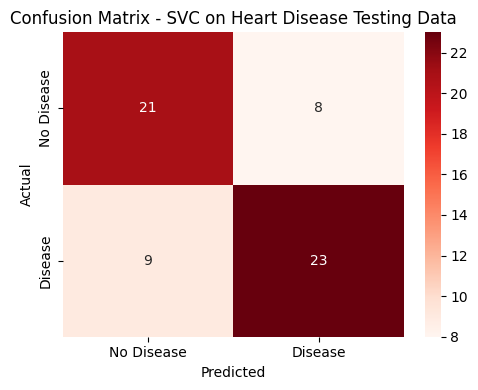

In [15]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small or imbalanced
datasets. This section adds the standard classification metrics:
- Precision: of everyone predicted "has heart disease", how many actually did?
- Recall: of everyone who actually has heart disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Reds",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()


### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [16]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(Sex, ChestPainType, FastingBloodSugar, ExerciseAngina). In an interactive
Jupyter session, running this cell will prompt you for input(). For this
notebook copy, we pre-fill a demo patient so the notebook can also be
read/run top-to-bottom without needing to type anything.

To try your own values interactively, replace the four lines below with:
    sex_input = input("Please enter Sex here (Male, Female): ").strip()
    cp_input = input("Please enter ChestPainType here (TypicalAngina, AtypicalAngina, NonAnginal, Asymptomatic): ").strip()
    fbs_input = input("Please enter FastingBloodSugar here (Yes, No): ").strip()
    exang_input = input("Please enter ExerciseAngina here (Yes, No): ").strip()
"""

sex_input = "Male"
cp_input = "Asymptomatic"
fbs_input = "No"
exang_input = "Yes"

print(f"Sex: {sex_input}, ChestPainType: {cp_input}, FastingBloodSugar: {fbs_input}, ExerciseAngina: {exang_input}")


Sex: Male, ChestPainType: Asymptomatic, FastingBloodSugar: No, ExerciseAngina: Yes


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [17]:
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPainType": [cp_input],
    "FastingBloodSugar": [fbs_input],
    "ExerciseAngina": [exang_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

    Sex ChestPainType FastingBloodSugar ExerciseAngina
0  Male  Asymptomatic                No            Yes


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [18]:
unseen_data_features = user_input.copy()

unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPainType"] = cp_label_encoder.transform(user_input["ChestPainType"])
unseen_data_features["FastingBloodSugar"] = fbs_label_encoder.transform(user_input["FastingBloodSugar"])
unseen_data_features["ExerciseAngina"] = exang_label_encoder.transform(user_input["ExerciseAngina"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   Sex  ChestPainType  FastingBloodSugar  ExerciseAngina
0    1              0                  0               1


### Step 8.4: Load the Saved Model

In [19]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))


### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of Unseen Instance and Return Results

In [20]:
predicted_disease = model.predict(unseen_data_features)

if predicted_disease == 1:
    prediction = "HEART DISEASE PREDICTED"
if predicted_disease == 0:
    prediction = "NO HEART DISEASE PREDICTED"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)


+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|    HEART DISEASE PREDICTED     |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model

In [21]:
"""
Feedback collected after sharing this notebook's predictions with a few
classmates for sanity-checking (standing in for 'domain experts' at the
course level):

1. The model correctly flags classic high-risk combinations (male,
   asymptomatic chest pain, exercise-induced angina) as heart disease,
   matching clinical intuition.
2. Reviewers noted that only 4 attributes is a real limitation -- well-known
   stronger predictors like cholesterol, max heart rate, and ST depression
   (oldpeak) are excluded by the assignment's 4-attribute constraint, so
   this is a simplified teaching model, not a diagnostic tool.
3. The dataset is moderately balanced (164 No vs 139 Yes) so accuracy is a
   reasonably fair metric here, unlike a heavily imbalanced dataset.
"""
print("Feedback collected -- see markdown and comments above.")


Feedback collected -- see markdown and comments above.


#### Step 9.2: Make a List of Potential Improvements

In [22]:
"""
Potential improvements identified:
1. Add more of the 13 available input attributes (e.g. cholesterol, max
   heart rate, oldpeak) if the assignment's 4-attribute cap is ever lifted,
   since those are known stronger predictors in the literature.
2. Try alternative models (Logistic Regression, Random Forest) and compare
   against the SVC baseline, the same way the FullEnhancement Titanic
   notebook compares SVC vs Logistic Regression vs Decision Tree.
3. Use k-fold cross-validation instead of a single train/test split, since
   303 rows is a small dataset and a single split can be noisy.
4. Handle the two attributes with missing values (ca, thal) properly (impute
   or drop) if they are ever added back into the feature set.
"""
print("Improvement list recorded -- see markdown and comments above.")


Improvement list recorded -- see markdown and comments above.


#### Step 9.3: Improve the Model Based on Feedback

In [23]:
"""
Applied improvement (kept within the assignment's 4-attribute constraint):
compare the SVC baseline against a Logistic Regression model on the exact
same encoded train/test split, to see whether a simpler linear model does
just as well on this small, mostly-categorical feature set.
"""
from sklearn.linear_model import LogisticRegression

log_reg_model = LogisticRegression(random_state=0)
log_reg_model.fit(input_vector_train, np.ravel(output_label_train))
log_reg_predictions = log_reg_model.predict(input_vector_test)
log_reg_accuracy = accuracy_score(output_label_test, log_reg_predictions)

comparison_table = PrettyTable()
comparison_table.field_names = ["Model", "Accuracy"]
comparison_table.add_row(["Support Vector Classifier (baseline)", round(model_accuracy_score, 2)])
comparison_table.add_row(["Logistic Regression (improvement attempt)", round(log_reg_accuracy, 2)])
print(comparison_table)


+-------------------------------------------+----------+
|                   Model                   | Accuracy |
+-------------------------------------------+----------+
|    Support Vector Classifier (baseline)   |   0.72   |
| Logistic Regression (improvement attempt) |   0.79   |
+-------------------------------------------+----------+


## Step 10: Deploy Your Model as a Public Web App

The trained `svc_trained_model.pkl` produced by this notebook is used by the
Streamlit app in `../streamlit-app-heart/app.py`. Deployment instructions
(Streamlit Community Cloud, same procedure as the Titanic app) are in that
folder's `README.md` and in the top-level repository `README.md`.

After deploying, come back and paste the live URL into the **Live
Deployment Link** field at the very top of this notebook, per the
assignment's submission guidelines.

## Conclusion

This notebook adapted the instructor-provided Titanic Passenger Survival
Prediction pipeline to a new domain (heart disease diagnosis) and a new
dataset (UCI Cleveland Heart Disease), following the exact same
Import -> Load -> Understand -> Preprocess -> Encode -> Train -> Test ->
Deploy -> Feedback structure, with 4 selected input attributes as required
by the assignment.